## Step 1: Import Libraries & Load the Dataset
First, we import `pandas` for data handling, `matplotlib`/`seaborn` for charts, and `scikit-learn` (`sklearn`) for machine learning tools.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load the dataset
df = pd.read_csv('patient_records_dataset.csv')

print(f"Dataset Shape: {df.shape[0]} patients, {df.shape[1]} columns")
df.head()

Dataset Shape: 500 patients, 15 columns


,patient_id,date_of_birth,age_years,gender,height_cm,weight_kg,blood_type,systolic_bp_mmHg,diastolic_bp_mmHg,fasting_blood_sugar_mg_dl,cholesterol_mg_dl,daily_salt_intake_g,activity_hours_per_week,smoker_status,hypertension_diagnosis
0,PAT-1001,1946-03-17,80,Male,166.5,80.2,O+,164,97,113.0,244.7,13.2,0,Non-Smoker,1
1,PAT-1002,1992-05-08,34,Female,156.8,57.8,O+,137,85,97.6,178.5,9.5,1,Non-Smoker,1
2,PAT-1003,1976-04-11,50,Female,165.9,85.9,O+,143,81,107.5,184.8,12.1,3,Non-Smoker,1
3,PAT-1004,1980-03-03,46,Female,153.7,69.6,A+,136,82,107.1,225.2,6.7,2,Non-Smoker,0
4,PAT-1005,1996-10-27,30,Male,180.9,89.0,O+,143,85,104.0,174.4,8.0,10,Former Smoker,1


In [3]:
# Check for missing values and inspect the target variable balance
print("Missing values per column:\n", df.isnull().sum().sum())
print("\nHypertension Diagnosis Counts (0 = No, 1 = Yes):")
print(df['hypertension_diagnosis'].value_counts())

Missing values per column:
 0

Hypertension Diagnosis Counts (0 = No, 1 = Yes):
hypertension_diagnosis
1    395
0    105
Name: count, dtype: int64


## Step 2: Data Preparation & Encoding
Machine learning models only understand **numbers**, not text or raw IDs.
1. **Drop non-predictive columns:** `patient_id` is just a label, and `date_of_birth` is redundant because we already have `age_years`.
2. **One-Hot Encoding (`pd.get_dummies`):** Converts text columns (`gender`, `blood_type`, `smoker_status`) into binary `0` and `1` columns.

In [ ]:
# 1. Drop ID and Date of Birth
df_clean = df.drop(columns=['patient_id', 'date_of_birth'])

# 2. Convert categorical text columns into numeric dummy variables
df_encoded = pd.get_dummies(
    df_clean
    , columns=['gender', 'blood_type', 'smoker_status']
    , drop_first=True
)

# Separate Features (X) from the Target Answer (y)
X = df_encoded.drop(columns=['hypertension_diagnosis'])
y = df_encoded['hypertension_diagnosis']

print(f"Features ready! Total input features: {X.shape[1]}")
X.head(3)

Features ready! Total input features: 19


,age_years,height_cm,weight_kg,systolic_bp_mmHg,diastolic_bp_mmHg,fasting_blood_sugar_mg_dl,cholesterol_mg_dl,daily_salt_intake_g,activity_hours_per_week,gender_Male,blood_type_A-,blood_type_AB+,blood_type_AB-,blood_type_B+,blood_type_B-,blood_type_O+,blood_type_O-,smoker_status_Former Smoker,smoker_status_Non-Smoker
0,80,166.5,80.2,164,97,113.0,244.7,13.2,0,True,False,False,False,False,False,True,False,False,True
1,34,156.8,57.8,137,85,97.6,178.5,9.5,1,False,False,False,False,False,False,True,False,False,True
2,50,165.9,85.9,143,81,107.5,184.8,12.1,3,False,False,False,False,False,False,True,False,False,True


## Step 3: Splitting into Train, Validation, and Test Sets
Think of this like preparing for an exam:
* **Training Set (70% — 350 patients):** The textbook the model studies to learn patterns.
* **Validation Set (15% — 75 patients):** A practice quiz used to compare different models and tune settings.
* **Test Set (15% — 75 patients):** The final locked exam! We only look at this at the very end to see how well our chosen model performs on brand-new patients.

> **Tip:** Using `stratify=y` ensures the ratio of hypertensive to non-hypertensive patients stays balanced across all three splits.

In [5]:
# First split: 70% Train, 30% Validation + Test
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

# Second split: Divide the 30% evenly into 15% Validation and 15% Test
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print(f"Training Set:   {len(X_train)} patients")
print(f"Validation Set: {len(X_val)} patients")
print(f"Test Set:       {len(X_test)} patients")

Training Set:   350 patients
Validation Set: 75 patients
Test Set:       75 patients


## Step 4: Feature Scaling
Notice that `cholesterol_mg_dl` ranges up to ~380, while `activity_hours_per_week` is between 0 and 10. Algorithms like Logistic Regression can get biased by larger numbers.

`StandardScaler` centers every feature around `0` with a standard deviation of `1`.  
**Crucial Rule:** Always `.fit()` the scaler **only on `X_train`** so information from the validation/test sets doesn't leak into training!

In [6]:
scaler = StandardScaler()

# Fit on training data and transform all three sets
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling complete!")

Feature scaling complete!


## Step 5: Model Training & Validation
Let's train two beginner-friendly classification models and evaluate both on the **Validation Set** to pick a winner:
1. **Logistic Regression:** Draws a smooth linear boundary to estimate probability.
2. **Decision Tree:** Learns step-by-step `if / else` rules (e.g., *Is systolic BP >= 130?*).

In [7]:
# --- Model 1: Logistic Regression ---
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)

val_preds_lr = log_reg.predict(X_val_scaled)
val_acc_lr = accuracy_score(y_val, val_preds_lr)

# --- Model 2: Decision Tree (max_depth=4 prevents overfitting) ---
dt_model = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_model.fit(X_train, y_train)  # Decision trees don't strictly need scaling

val_preds_dt = dt_model.predict(X_val)
val_acc_dt = accuracy_score(y_val, val_preds_dt)

print(f"Logistic Regression Validation Accuracy: {val_acc_lr:.2%}")
print(f"Decision Tree Validation Accuracy:       {val_acc_dt:.2%}")

Logistic Regression Validation Accuracy: 84.00%
Decision Tree Validation Accuracy:       85.33%


## Step 6: Cross-Validation (Checking Consistency)
Before locking in our choice, we run **5-Fold Cross-Validation** on the training data. This splits the training set into 5 chunks, trains 5 separate times, and gives us an average accuracy score.

In [8]:
cv_scores_lr = cross_val_score(log_reg, X_train_scaled, y_train, cv=5, scoring='accuracy')
cv_scores_dt = cross_val_score(dt_model, X_train, y_train, cv=5, scoring='accuracy')

print(f"Logistic Regression 5-Fold CV Mean Accuracy: {cv_scores_lr.mean():.2%} (+/- {cv_scores_lr.std():.2%})")
print(f"Decision Tree 5-Fold CV Mean Accuracy:       {cv_scores_dt.mean():.2%} (+/- {cv_scores_dt.std():.2%})")

Logistic Regression 5-Fold CV Mean Accuracy: 88.86% (+/- 2.29%)
Decision Tree 5-Fold CV Mean Accuracy:       88.00% (+/- 1.46%)


## Step 7: Final Evaluation on the Unseen Test Set
Now we evaluate our winning model (**Logistic Regression**) on the untouched **Test Set (`X_test_scaled`)** and visualize its mistakes using a **Confusion Matrix**.

In [9]:
# Predict on the final Test Set
final_test_preds = log_reg.predict(X_test_scaled)
final_test_acc = accuracy_score(y_test, final_test_preds)

print(f"FINAL TEST ACCURACY: {final_test_acc:.2%}\n")
print("Detailed Classification Report:")
print(classification_report(y_test, final_test_preds, target_names=['No Hypertension (0)', 'Hypertension (1)']))

FINAL TEST ACCURACY: 92.00%

Detailed Classification Report:
                     precision    recall  f1-score   support

No Hypertension (0)       0.78      0.88      0.82        16
   Hypertension (1)       0.96      0.93      0.95        59

           accuracy                           0.92        75
          macro avg       0.87      0.90      0.89        75
       weighted avg       0.92      0.92      0.92        75



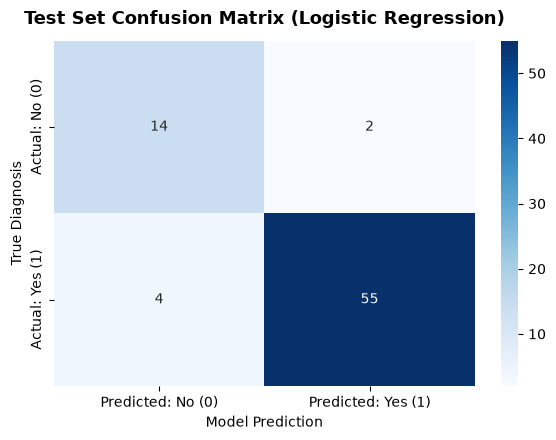

In [10]:
# Plot the Confusion Matrix
cm = confusion_matrix(y_test, final_test_preds)

plt.figure(figsize=(6, 4.5))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=['Predicted: No (0)', 'Predicted: Yes (1)'],
    yticklabels=['Actual: No (0)', 'Actual: Yes (1)']
)
plt.title('Test Set Confusion Matrix (Logistic Regression)', fontsize=13, fontweight='bold', pad=12)
plt.ylabel('True Diagnosis')
plt.xlabel('Model Prediction')
plt.tight_layout()
plt.show()